# 02_data_cleaning_eda

## Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

print("All libraries imported successfully!")

All libraries imported successfully!


## Loading the original dataset

In [2]:
df = pd.read_csv("../data/raw/dataset.csv")

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

Dataset loaded successfully!
Original shape: (4920, 18)


### Creating a working copy

In [3]:
clean_df = df.copy()

print("Working copy created!")
print("Shape:", clean_df.shape)

Working copy created!
Shape: (4920, 18)


### Checking data types

In [4]:
clean_df.dtypes

Disease       object
Symptom_1     object
Symptom_2     object
Symptom_3     object
Symptom_4     object
Symptom_5     object
Symptom_6     object
Symptom_7     object
Symptom_8     object
Symptom_9     object
Symptom_10    object
Symptom_11    object
Symptom_12    object
Symptom_13    object
Symptom_14    object
Symptom_15    object
Symptom_16    object
Symptom_17    object
dtype: object

In [5]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Disease     4920 non-null   object
 1   Symptom_1   4920 non-null   object
 2   Symptom_2   4920 non-null   object
 3   Symptom_3   4920 non-null   object
 4   Symptom_4   4572 non-null   object
 5   Symptom_5   3714 non-null   object
 6   Symptom_6   2934 non-null   object
 7   Symptom_7   2268 non-null   object
 8   Symptom_8   1944 non-null   object
 9   Symptom_9   1692 non-null   object
 10  Symptom_10  1512 non-null   object
 11  Symptom_11  1194 non-null   object
 12  Symptom_12  744 non-null    object
 13  Symptom_13  504 non-null    object
 14  Symptom_14  306 non-null    object
 15  Symptom_15  240 non-null    object
 16  Symptom_16  192 non-null    object
 17  Symptom_17  72 non-null     object
dtypes: object(18)
memory usage: 692.0+ KB


### Standardising column names

In [6]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.replace(" ", "_")
)

print(clean_df.columns.tolist())

['Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']


### Identifying symptom columns

In [7]:
target_column = "Disease"

symptom_columns = [
    col for col in clean_df.columns
    if col.startswith("Symptom_")
]

print("Target:", target_column)
print("Number of symptom columns:", len(symptom_columns))
print(symptom_columns)

Target: Disease
Number of symptom columns: 17
['Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']


### Cleaning disease names

In [8]:
clean_df[target_column] = (
    clean_df[target_column]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Disease names cleaned!")

Disease names cleaned!


In [9]:
clean_df[target_column].unique()

<StringArray>
[                       'fungal infection',
                                 'allergy',
                                    'gerd',
                     'chronic cholestasis',
                           'drug reaction',
                     'peptic ulcer diseae',
                                    'aids',
                                'diabetes',
                         'gastroenteritis',
                        'bronchial asthma',
                            'hypertension',
                                'migraine',
                    'cervical spondylosis',
            'paralysis (brain hemorrhage)',
                                'jaundice',
                                 'malaria',
                             'chicken pox',
                                  'dengue',
                                 'typhoid',
                             'hepatitis a',
                             'hepatitis b',
                             'hepatitis c',
                  

### Cleaning symptom values

In [10]:
for col in symptom_columns:

    clean_df[col] = (
        clean_df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

print("All symptom values standardised!")

All symptom values standardised!


### Handling missing values

In [11]:
missing_values = clean_df.isnull().sum()

print(missing_values)

Disease          0
Symptom_1        0
Symptom_2        0
Symptom_3        0
Symptom_4      348
Symptom_5     1206
Symptom_6     1986
Symptom_7     2652
Symptom_8     2976
Symptom_9     3228
Symptom_10    3408
Symptom_11    3726
Symptom_12    4176
Symptom_13    4416
Symptom_14    4614
Symptom_15    4680
Symptom_16    4728
Symptom_17    4848
dtype: int64


### Visualising them

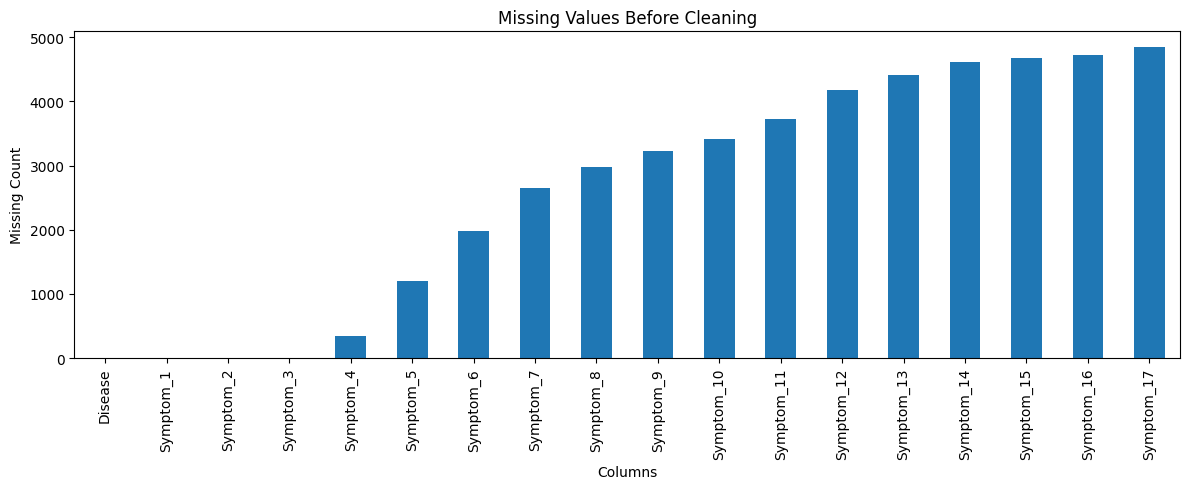

In [12]:
plt.figure(figsize=(12, 5))

missing_values.plot(kind="bar")

plt.title("Missing Values Before Cleaning")
plt.xlabel("Columns")
plt.ylabel("Missing Count")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [13]:
clean_df[symptom_columns] = (
    clean_df[symptom_columns].fillna("")
)

print("Missing symptom values handled!")

Missing symptom values handled!


In [14]:
print(clean_df.isnull().sum())

Disease       0
Symptom_1     0
Symptom_2     0
Symptom_3     0
Symptom_4     0
Symptom_5     0
Symptom_6     0
Symptom_7     0
Symptom_8     0
Symptom_9     0
Symptom_10    0
Symptom_11    0
Symptom_12    0
Symptom_13    0
Symptom_14    0
Symptom_15    0
Symptom_16    0
Symptom_17    0
dtype: int64


In [15]:
before = len(clean_df)

clean_df = clean_df.dropna(subset=[target_column])

after = len(clean_df)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

Rows before: 4920
Rows after: 4920
Rows removed: 0


### Investigating duplicate records

In [16]:
exact_duplicates = clean_df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

Exact duplicate rows: 4616


In [17]:
pattern_duplicates = clean_df.duplicated(
    subset=symptom_columns,
    keep=False
)

print(
    "Rows with repeated symptom combinations:",
    pattern_duplicates.sum()
)

Rows with repeated symptom combinations: 4920


### Checking conflicting symptom patterns

In [18]:
pattern_disease_counts = (
    clean_df
    .groupby(symptom_columns, dropna=False)[target_column]
    .nunique()
)

conflicting_patterns = pattern_disease_counts[
    pattern_disease_counts > 1
]

print("Conflicting symptom patterns:", len(conflicting_patterns))

Conflicting symptom patterns: 0


In [19]:
if len(conflicting_patterns) > 0:

    conflicting_data = clean_df.merge(
        conflicting_patterns.reset_index(name="disease_count"),
        on=symptom_columns,
        how="inner"
    )

    display(conflicting_data.head(20))

else:

    print("No conflicting symptom patterns found.")

No conflicting symptom patterns found.


### Disease distribution analysis

In [20]:
disease_counts = clean_df[target_column].value_counts()

print("Number of diseases:", len(disease_counts))

display(disease_counts)

Number of diseases: 41


Disease
fungal infection                           120
allergy                                    120
gerd                                       120
chronic cholestasis                        120
drug reaction                              120
peptic ulcer diseae                        120
aids                                       120
diabetes                                   120
gastroenteritis                            120
bronchial asthma                           120
hypertension                               120
migraine                                   120
cervical spondylosis                       120
paralysis (brain hemorrhage)               120
jaundice                                   120
malaria                                    120
chicken pox                                120
dengue                                     120
typhoid                                    120
hepatitis a                                120
hepatitis b                                120
hepat

### Most frequent symptoms

In [22]:
symptom_frequency = (
    clean_df[symptom_columns]
    .stack()
    .value_counts()
    .drop("")
)

print("Total unique symptoms:", len(symptom_frequency))

display(symptom_frequency.head(20))

Total unique symptoms: 131


fatigue              1932
vomiting             1914
high_fever           1362
loss_of_appetite     1152
nausea               1146
headache             1134
abdominal_pain       1032
yellowish_skin        912
yellowing_of_eyes     816
chills                798
skin_rash             786
malaise               702
chest_pain            696
joint_pain            684
itching               678
sweating              678
dark_urine            570
diarrhoea             564
cough                 564
muscle_pain           474
Name: count, dtype: Int64

### Number of symptoms per record

In [24]:
clean_df["Total_Symptoms"] = (
    clean_df[symptom_columns]
    .ne("")
    .sum(axis=1)
)

clean_df[["Disease", "Total_Symptoms"]].head()

,Disease,Total_Symptoms
0,fungal infection,4
1,fungal infection,3
2,fungal infection,3
3,fungal infection,3
4,fungal infection,3


### Average symptoms per disease

In [26]:
average_symptoms = (
    clean_df.groupby("Disease")["Total_Symptoms"]
    .mean()
    .sort_values(ascending=False)
)

display(average_symptoms)

Disease
common cold                                 16.6
tuberculosis                                15.6
dengue                                     13.55
hepatitis e                                 12.6
hypothyroidism                              12.6
hypoglycemia                                11.6
hepatitis b                                 11.6
hepatitis a                                 10.6
hyperthyroidism                             10.6
typhoid                                     10.6
pneumonia                                   10.6
chicken pox                                10.55
diabetes                                     9.6
hepatitis d                                 8.55
migraine                                    8.55
malaria                                      7.6
jaundice                                     7.6
chronic cholestasis                         6.65
alcoholic hepatitis                         6.65
varicose veins                               6.6
psoriasis   

### Saving the cleaned dataset

In [28]:
final_clean_df = clean_df.drop(
    columns=["Total_Symptoms"],
    errors="ignore"
)

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../images", exist_ok=True)

final_clean_df.to_csv(
    "../data/processed/cleaned_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final shape:", final_clean_df.shape)

Cleaned dataset saved successfully!
Final shape: (4920, 18)


### Saving the EDA report

In [29]:
os.makedirs("../reports", exist_ok=True)

with open("../reports/eda_summary.txt", "w") as f:

    f.write("MEDICAL SYMPTOM DATASET - EDA SUMMARY\n")
    f.write("=" * 45 + "\n\n")

    f.write(f"Total records: {len(final_clean_df)}\n")
    f.write(f"Total diseases: {final_clean_df['Disease'].nunique()}\n")
    f.write(f"Symptom columns: {len(symptom_columns)}\n")
    f.write(f"Unique symptoms: {len(symptom_frequency)}\n")
    f.write(f"Exact duplicates found: {exact_duplicates}\n")
    f.write(f"Conflicting patterns: {len(conflicting_patterns)}\n\n")

    f.write("Disease distribution:\n")
    f.write(disease_counts.to_string())

print("EDA report saved!")

EDA report saved!


In [30]:
print("CLEANING SUMMARY")
print("-" * 40)

print("Original records:", len(df))
print("Cleaned records:", len(final_clean_df))

print("Disease classes:", final_clean_df["Disease"].nunique())

print("Symptom columns:", len(symptom_columns))

print("Unique symptoms:", len(symptom_frequency))

print("Exact duplicates:", exact_duplicates)

print("Conflicting symptom patterns:", len(conflicting_patterns))

print("\nSaved file:")
print("../data/processed/cleaned_dataset.csv")

CLEANING SUMMARY
----------------------------------------
Original records: 4920
Cleaned records: 4920
Disease classes: 41
Symptom columns: 17
Unique symptoms: 131
Exact duplicates: 4616
Conflicting symptom patterns: 0

Saved file:
../data/processed/cleaned_dataset.csv


In [33]:
import os

os.makedirs("../images", exist_ok=True)

print("Images folder is ready!")

Images folder is ready!


### Graph 1: Disease distribution

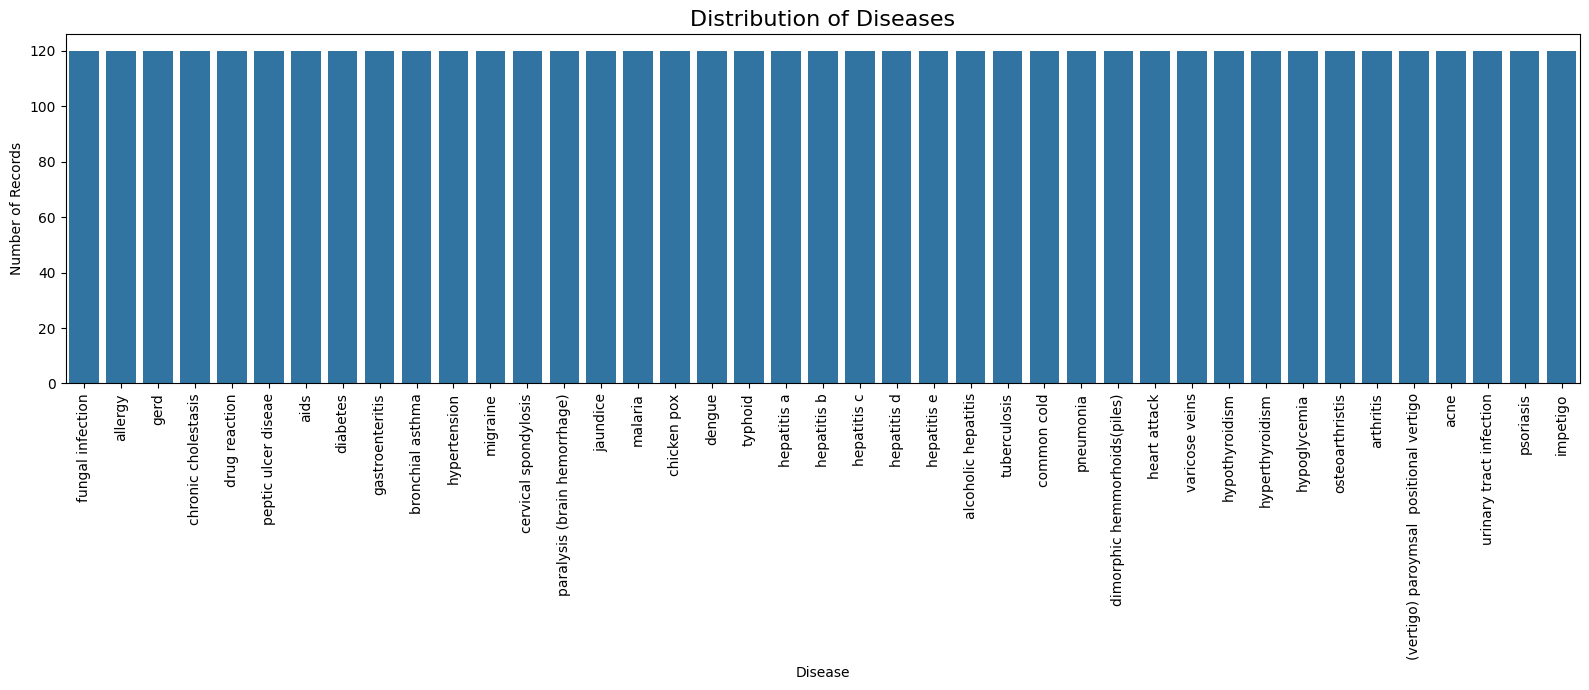

In [39]:
plt.figure(figsize=(16, 7))

disease_counts = clean_df["Disease"].value_counts()

sns.barplot(
    x=disease_counts.index,
    y=disease_counts.values
)

plt.title("Distribution of Diseases", fontsize=16)
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig("../images/disease_distribution.png", dpi=300)

plt.show()
plt.close()

### Graph 2: Top 20 symptoms

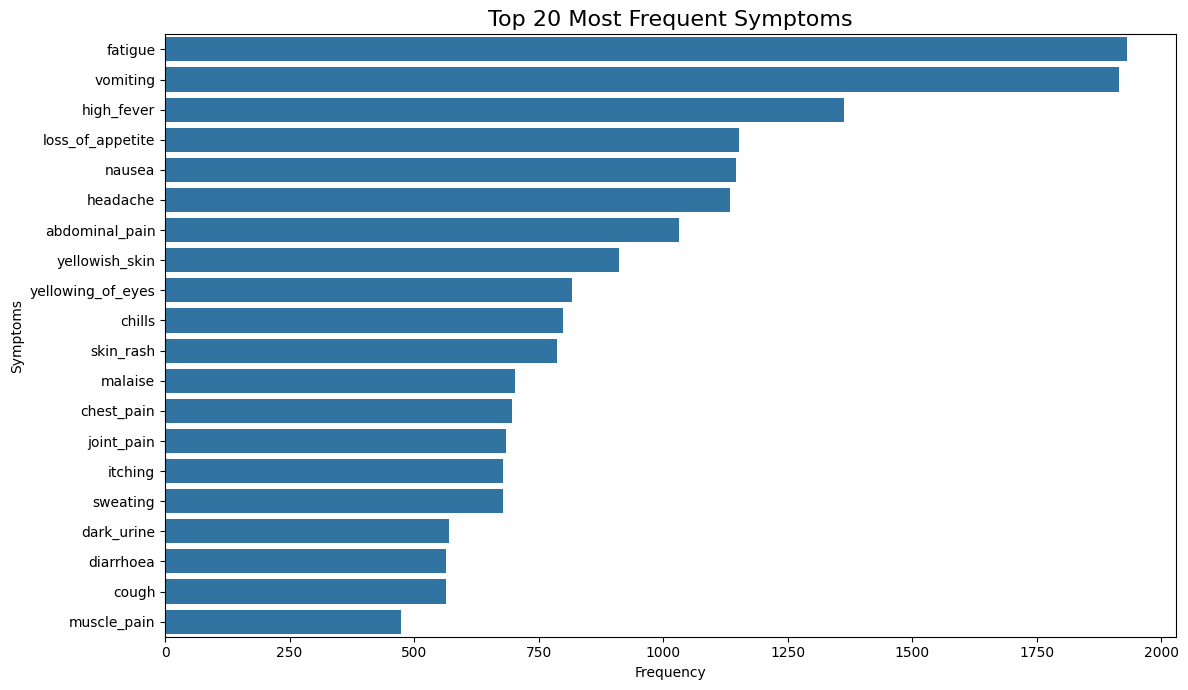

In [35]:
plt.figure(figsize=(12, 7))

symptom_frequency = (
    clean_df[symptom_columns]
    .stack()
    .value_counts()
    .drop("", errors="ignore")
)

top_20_symptoms = symptom_frequency.head(20)

sns.barplot(
    x=top_20_symptoms.values,
    y=top_20_symptoms.index
)

plt.title("Top 20 Most Frequent Symptoms", fontsize=16)
plt.xlabel("Frequency")
plt.ylabel("Symptoms")

plt.tight_layout()

plt.savefig("../images/top_20_symptoms.png", dpi=300)

plt.show()
plt.close()

### Graph 3: Number of symptoms per record

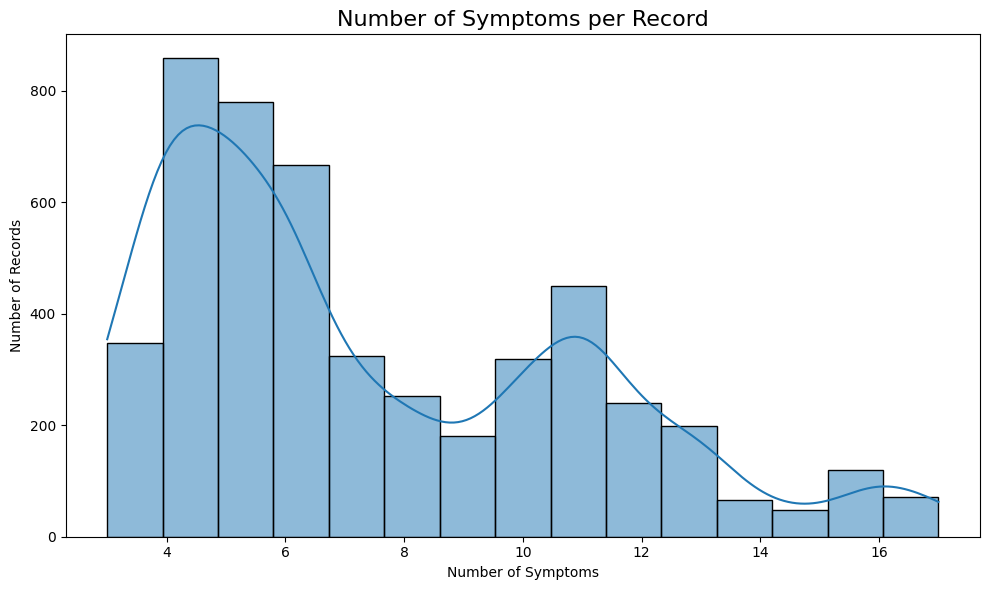

In [36]:
clean_df["Total_Symptoms"] = (
    clean_df[symptom_columns].ne("").sum(axis=1)
)

plt.figure(figsize=(10, 6))

sns.histplot(
    clean_df["Total_Symptoms"],
    bins=15,
    kde=True
)

plt.title("Number of Symptoms per Record", fontsize=16)
plt.xlabel("Number of Symptoms")
plt.ylabel("Number of Records")

plt.tight_layout()

plt.savefig("../images/symptoms_per_record.png", dpi=300)

plt.show()
plt.close()

### Graph 4: Average symptoms per disease

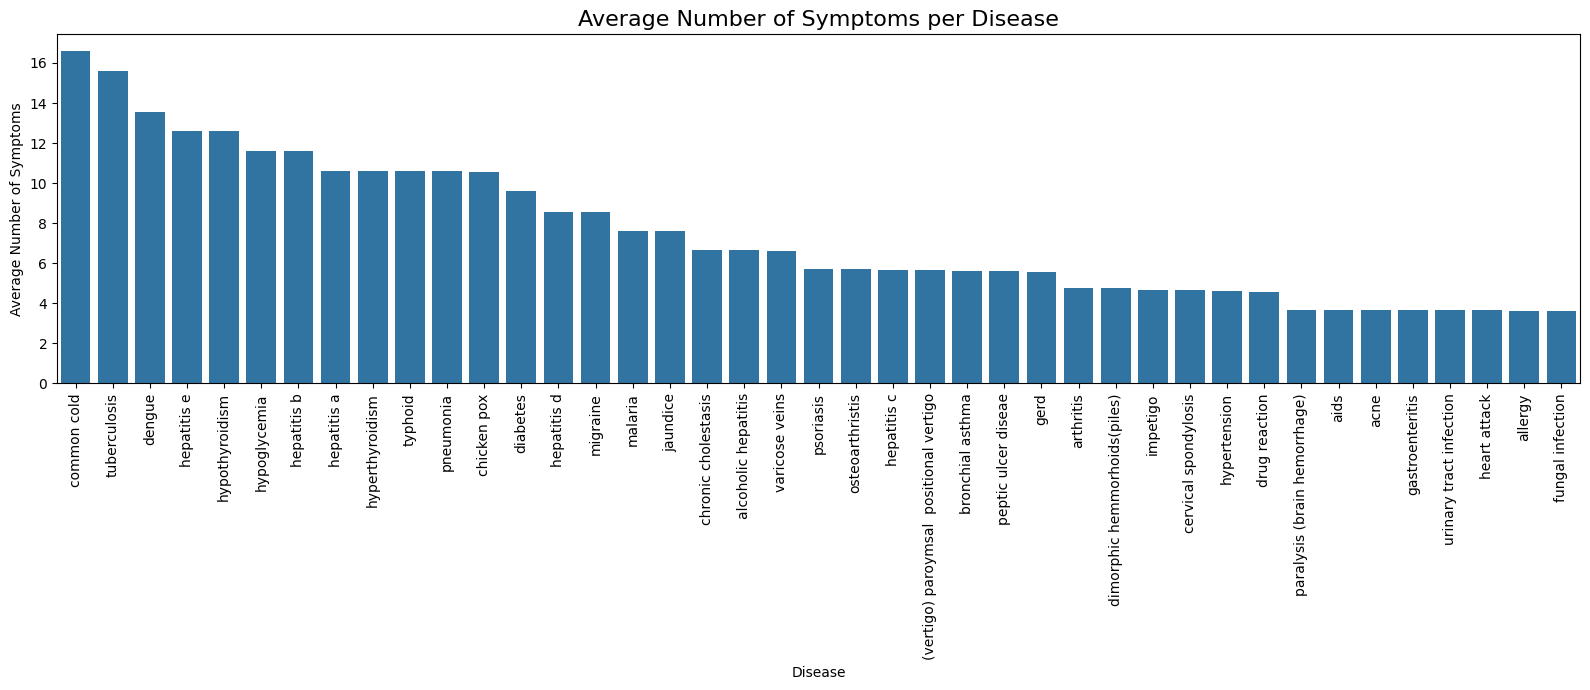

In [37]:
average_symptoms = (
    clean_df.groupby("Disease")["Total_Symptoms"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(16, 7))

sns.barplot(
    x=average_symptoms.index,
    y=average_symptoms.values
)

plt.title("Average Number of Symptoms per Disease", fontsize=16)
plt.xlabel("Disease")
plt.ylabel("Average Number of Symptoms")
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig("../images/average_symptoms_per_disease.png", dpi=300)

plt.show()
plt.close()

### Verifying all four images

In [38]:
image_folder = "../images"

print("IMAGES SAVED SUCCESSFULLY")
print("-" * 40)

for file in os.listdir(image_folder):
    if file.endswith(".png"):
        print("✔", file)

IMAGES SAVED SUCCESSFULLY
----------------------------------------
✔ average_symptoms_per_disease.png
✔ disease_distribution.png
✔ symptoms_per_record.png
✔ top_20_symptoms.png
